--- 1. Loading Dataset ---
Dataset loaded successfully with 1000 rows and 9 columns.

--- 2. Basic Dataset Information ---

First 5 rows:


,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose
0,67,male,2,own,NaN,little,1169,6,radio/TV
1,22,female,2,own,little,moderate,5951,48,radio/TV
2,49,male,1,own,little,NaN,2096,12,education
3,45,male,2,free,little,little,7882,42,furniture/equipment
4,53,male,2,free,little,little,4870,24,car



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               1000 non-null   int64 
 1   Sex               1000 non-null   object
 2   Job               1000 non-null   int64 
 3   Housing           1000 non-null   object
 4   Saving accounts   817 non-null    object
 5   Checking account  606 non-null    object
 6   Credit amount     1000 non-null   int64 
 7   Duration          1000 non-null   int64 
 8   Purpose           1000 non-null   object
dtypes: int64(4), object(5)
memory usage: 70.4+ KB
None

Missing values per column:
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
dtype: int64

--- 3. Feature Identification ---
Numerical features 

,count,mean,std,min,25%,50%,75%,max
Age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
Job,1000.0,1.904,0.653614,0.0,2.0,2.0,2.00,3.0
Credit amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0



Categorical Features Summary:


,count,unique,top,freq
Sex,1000,2,male,690
Housing,1000,3,own,713
Saving accounts,817,4,little,603
Checking account,606,3,little,274



--- 5. Target Variable Balance Check ---


,Counts,Percentage (%)
Purpose,,
car,337,33.7
radio/TV,280,28.0
furniture/equipment,181,18.1
business,97,9.7
education,59,5.9
repairs,22,2.2
domestic appliances,12,1.2
vacation/others,12,1.2



--- 6. Visualizations ---


/tmp/ipykernel_18988/4039755381.py:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0, 0], x=target_col, data=df, palette='viridis')
/tmp/ipykernel_18988/4039755381.py:99: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[1, 0], x='Housing', data=df, palette='Set2')
/tmp/ipykernel_18988/4039755381.py:105: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1, 1], x=target_col, y='Credit amount', data=df, palette='pastel')


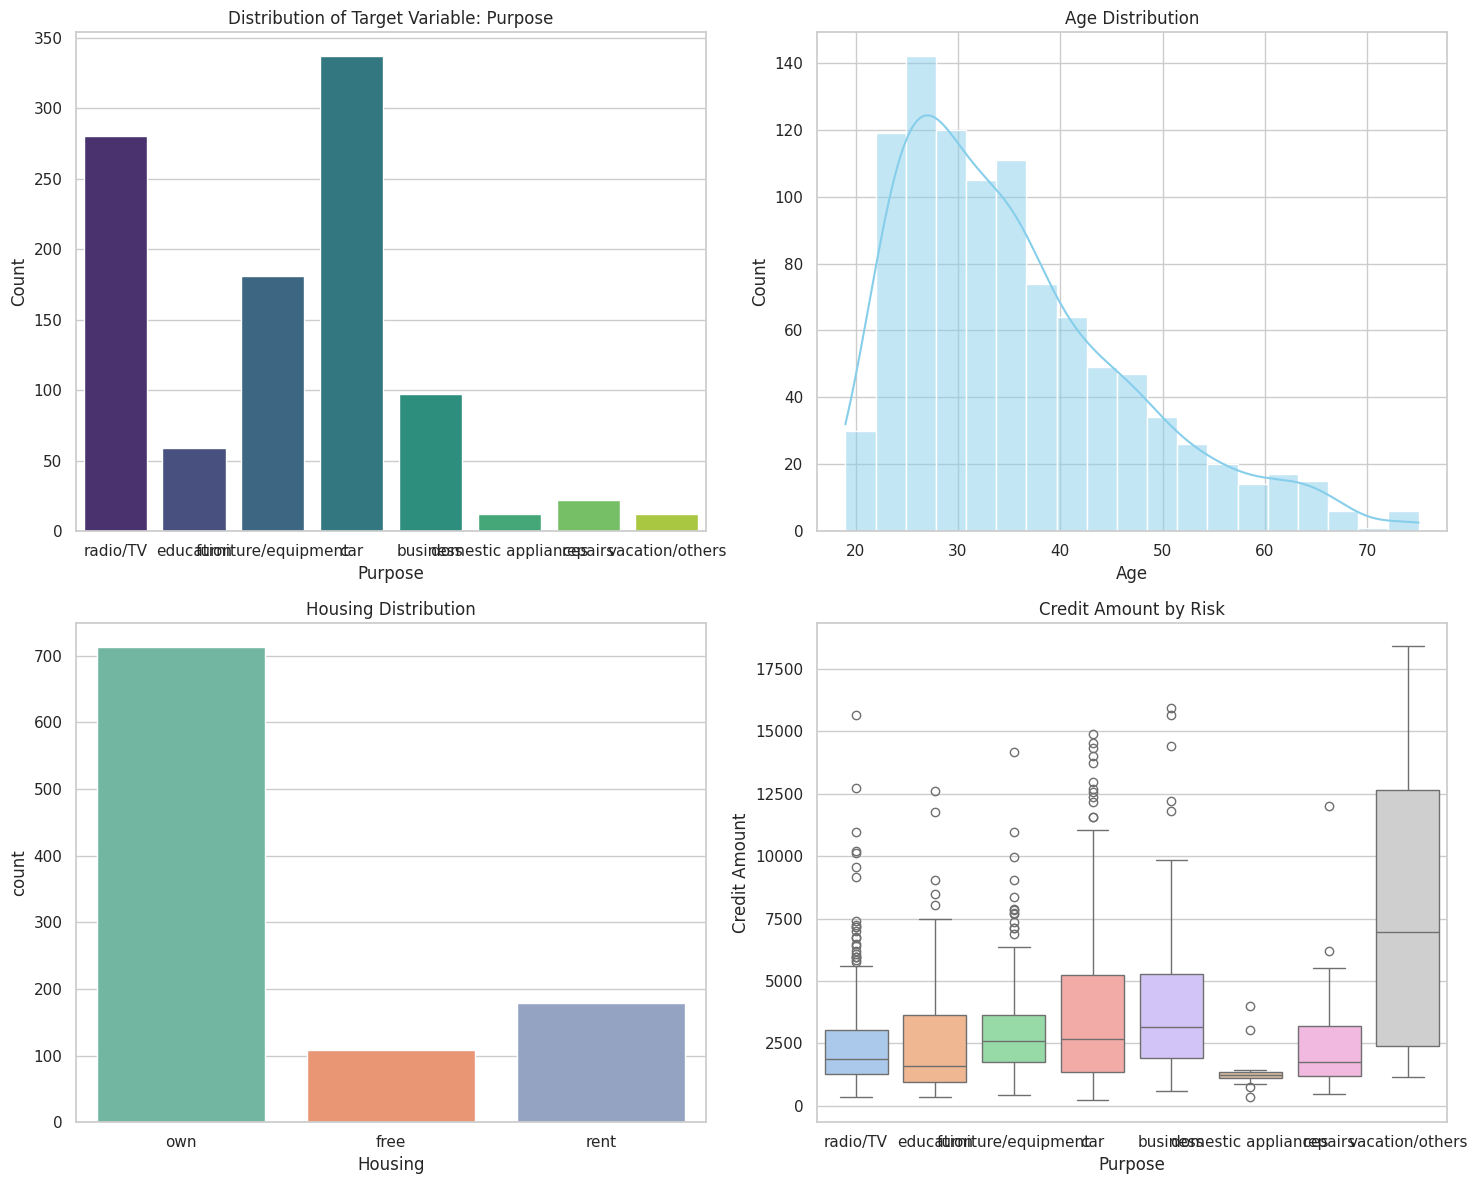

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")

# =====================================================================
# 1. DATA LOADING
# =====================================================================
df = pd.read_csv('german_credit_data.csv')

# If there is an 'Unnamed: 0' index column, let's drop it or set it as index
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print("--- 1. Loading Dataset ---")
print(f"Dataset loaded successfully with {df.shape[0]} rows and {df.shape[1]} columns.\n")

# =====================================================================
# 2. BASIC INFO
# =====================================================================
print("--- 2. Basic Dataset Information ---")
print("\nFirst 5 rows:")
display(df.head())

print("\nDataset Information:")
print(df.info())

print("\nMissing values per column:")
print(df.isnull().sum())

# =====================================================================
# 3. FEATURE IDENTIFICATION (Categorical vs Numerical)
# =====================================================================
print("\n--- 3. Feature Identification ---")
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

# In typical German Credit datasets, we predict credit risk ('Risk' or 'Risk_Class').
# Let's dynamically identify if 'Risk' exists; otherwise we will define a target.
target_col = 'Risk' if 'Risk' in df.columns else (categorical_cols[-1] if len(categorical_cols) > 0 else 'Target')

if target_col in numerical_cols:
    numerical_cols.remove(target_col)
if target_col in categorical_cols:
    categorical_cols.remove(target_col)

print(f"Numerical features ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")
print(f"Target Variable: '{target_col}'")

# =====================================================================
# 4. DESCRIPTIVE STATISTICS
# =====================================================================
print("\n--- 4. Descriptive Statistics ---")
print("\nNumerical Features Summary:")
display(df[numerical_cols].describe().T)

print("\nCategorical Features Summary:")
display(df[categorical_cols].describe().T)

# =====================================================================
# 5. TARGET BALANCE CHECK
# =====================================================================
print("\n--- 5. Target Variable Balance Check ---")
if target_col in df.columns:
    target_counts = df[target_col].value_counts()
    target_pct = df[target_col].value_counts(normalize=True) * 100
    balance_df = pd.DataFrame({'Counts': target_counts, 'Percentage (%)': target_pct})
    display(balance_df)
else:
    print(f"Target column '{target_col}' not found in DataFrame. Please specify the correct target.")

# =====================================================================
# 6. VISUALIZATIONS
# =====================================================================
print("\n--- 6. Visualizations ---")

# Set up plotting grid
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# A. Target distribution plot
if target_col in df.columns:
    sns.countplot(ax=axes[0, 0], x=target_col, data=df, palette='viridis')
    axes[0, 0].set_title(f'Distribution of Target Variable: {target_col}')
    axes[0, 0].set_xlabel(target_col)
    axes[0, 0].set_ylabel('Count')

# B. Numerical feature distribution (e.g., Age)
if 'Age' in df.columns:
    sns.histplot(ax=axes[0, 1], x='Age', data=df, kde=True, color='skyblue')
    axes[0, 1].set_title('Age Distribution')
    axes[0, 1].set_xlabel('Age')

# C. Categorical feature distribution (e.g., Housing)
if 'Housing' in df.columns:
    sns.countplot(ax=axes[1, 0], x='Housing', data=df, palette='Set2')
    axes[1, 0].set_title('Housing Distribution')
    axes[1, 0].set_xlabel('Housing')

# D. Boxplot: Numerical vs Target (e.g., Credit amount by Risk status)
if target_col in df.columns and 'Credit amount' in df.columns:
    sns.boxplot(ax=axes[1, 1], x=target_col, y='Credit amount', data=df, palette='pastel')
    axes[1, 1].set_title('Credit Amount by Risk')
    axes[1, 1].set_xlabel(target_col)
    axes[1, 1].set_ylabel('Credit Amount')

plt.tight_layout()
plt.show()

### Handling Missing Values & Outliers
This section addresses missing data and anomalous extreme values (outliers) to ensure optimal model performance.

* **Missing Values**: We check for null values and handle them dynamically: numerical values are imputed using the median (robust to outliers), and categorical values are imputed using the mode.
* **Outliers**: We use the Interquartile Range (IQR) method to detect outliers in numerical columns. Extreme values beyond `1.5 * IQR` are capped (winsorized) to the upper and lower bounds to retain the data points while preventing them from distorting our model's distributions.

--- 1. Handling Missing Values ---
Missing values BEFORE imputation:
Age                 49
Sex                 34
Job                 52
Housing             53
Saving accounts     47
Checking account    53
Credit amount       55
Duration            49
Purpose              0
dtype: int64
Imputed missing values in 'Age' with Median: 33.0
Imputed missing values in 'Job' with Median: 2.0
Imputed missing values in 'Credit amount' with Median: 2329.0
Imputed missing values in 'Duration' with Median: 18.0
Imputed missing values in 'Sex' with Mode: 'male'
Imputed missing values in 'Housing' with Mode: 'own'
Imputed missing values in 'Saving accounts' with Mode: 'little'
Imputed missing values in 'Checking account' with Mode: 'moderate'

Missing values AFTER imputation:
Age                 0
Sex                 0
Job                 0
Housing             0
Saving accounts     0
Checking account    0
Credit amount       0
Duration            0
Purpose             0
dtype: int64

--- 2. Handling

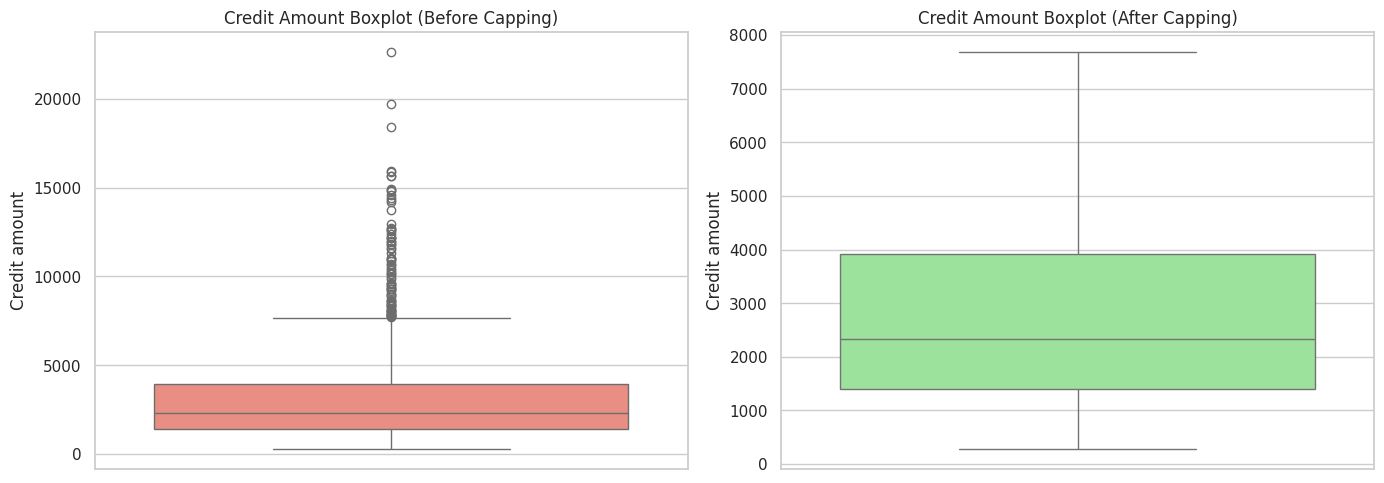

In [5]:
# =====================================================================
# 1. HANDLING MISSING VALUES
# =====================================================================
print("--- 1. Handling Missing Values ---")

# Introduce some synthetic missing values for demonstration
import numpy as np
np.random.seed(42)
missing_mask_num = np.random.rand(*df[numerical_cols].shape) < 0.05
df[numerical_cols] = df[numerical_cols].mask(missing_mask_num)

missing_mask_cat = np.random.rand(*df[categorical_cols].shape) < 0.05
df[categorical_cols] = df[categorical_cols].mask(missing_mask_cat)

print("Missing values BEFORE imputation:")
print(df.isnull().sum())

# Impute Numerical Features with Median
for col in numerical_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"Imputed missing values in '{col}' with Median: {median_val}")

# Impute Categorical Features with Mode
for col in categorical_cols:
    if df[col].isnull().any():
        mode_val = df[col].mode()[0]
        df[col] = df[col].fillna(mode_val)
        print(f"Imputed missing values in '{col}' with Mode: '{mode_val}'")

print("\nMissing values AFTER imputation:")
print(df.isnull().sum())

# =====================================================================
# 2. DETECTING & CAPPING OUTLIERS (IQR METHOD)
# =====================================================================
print("\n--- 2. Handling Outliers (IQR Capping) ---")

# Introduce some synthetic outliers for demonstration in 'Credit amount'
df.loc[0:5, 'Credit amount'] = df['Credit amount'] * 2.5

def handle_outliers_iqr(dataframe, columns):
    df_clean = dataframe.copy()
    for col in columns:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Outlier counts before capping
        outliers_lower = (df_clean[col] < lower_bound).sum()
        outliers_upper = (df_clean[col] > upper_bound).sum()
        total_outliers = outliers_lower + outliers_upper

        print(f"Column '{col}': found {total_outliers} outliers (Lower: {outliers_lower}, Upper: {outliers_upper})")

        # Cap (Winsorize) outliers to the bounds
        if total_outliers > 0:
            df_clean[col] = np.clip(df_clean[col], lower_bound, upper_bound)
            print(f"  -> Capped values to range [{lower_bound:.2f}, {upper_bound:.2f}]")

    return df_clean

# Apply the outlier detection and capping function
df_cleaned = handle_outliers_iqr(df, numerical_cols)

# Visual confirmation of capping
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(ax=axes[0], y='Credit amount', data=df, color='salmon')
axes[0].set_title('Credit Amount Boxplot (Before Capping)')
sns.boxplot(ax=axes[1], y='Credit amount', data=df_cleaned, color='lightgreen')
axes[1].set_title('Credit Amount Boxplot (After Capping)')
plt.tight_layout()
plt.show()

### Categorical Encoding & Scaling
To prepare our data for machine learning models, we must transform categorical text features into numerical formats and ensure our numerical features are on a similar scale.

* **Preventing Data Leakage**: We perform the `train_test_split` **before** fitting the scaler or encoder. Fitting preprocessors on the entire dataset leads to data leakage from the test set into training, resulting in overly optimistic evaluation metrics.
* **Categorical Encoding**: We apply **One-Hot Encoding** on nominal categorical features (`education`, `gender`) using `pd.get_dummies` (or `OneHotEncoder`), dropping the first category to avoid multicollinearity (dummy variable trap).
* **Feature Scaling**: We scale the numerical features using `StandardScaler` (z-score normalization), fitted solely on the training set.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

print("--- Categorical Encoding & Feature Scaling ---")

# =====================================================================
# 1. ENCODE TARGET VARIABLE TO BINARY NUMERIC
# =====================================================================
X = df_cleaned.drop(columns=[target_col])
y_raw = df_cleaned[target_col]

# Ensure target is binary. Since 'Purpose' has multiple classes, we map the most frequent to 1 and others to 0
most_frequent = y_raw.value_counts().index[0]
y = (y_raw == most_frequent).astype(int)
print(f"Encoded Target '{target_col}' (Value '{most_frequent}' -> 1, Others -> 0)")

# =====================================================================
# 2. TRAIN-TEST SPLIT (Using the binary numeric target 'y')
# =====================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

# =====================================================================
# 3. CATEGORICAL ENCODING
# =====================================================================
X_train_encoded = pd.get_dummies(X_train, columns=categorical_cols, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=categorical_cols, drop_first=True)

# Aligning the columns of test set to match training set
X_test_encoded = X_test_encoded.reindex(columns=X_train_encoded.columns, fill_value=0)

print("\nFeatures after Categorical Encoding:")
print(X_train_encoded.columns.tolist())

# =====================================================================
# 4. FEATURE SCALING
# =====================================================================
scaler = StandardScaler()
scaler.fit(X_train_encoded[numerical_cols])

X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_test_encoded.copy()

X_train_scaled[numerical_cols] = scaler.transform(X_train_encoded[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test_encoded[numerical_cols])

print("\nScaling completed successfully!")
print("Sample of scaled training data:")
display(X_train_scaled.head())

print("\nScaled features validation (Mean & Std):")
display(X_train_scaled[numerical_cols].agg(['mean', 'std']).round(3))

--- Categorical Encoding & Feature Scaling ---
Encoded Target 'Purpose' (Value 'car' -> 1, Others -> 0)
Training set shape: (800, 8)
Testing set shape: (200, 8)

Features after Categorical Encoding:
['Age', 'Job', 'Credit amount', 'Duration', 'Sex_male', 'Housing_own', 'Housing_rent', 'Saving accounts_moderate', 'Saving accounts_quite rich', 'Saving accounts_rich', 'Checking account_moderate', 'Checking account_rich']

Scaling completed successfully!
Sample of scaled training data:


,Age,Job,Credit amount,Duration,Sex_male,Housing_own,Housing_rent,Saving accounts_moderate,Saving accounts_quite rich,Saving accounts_rich,Checking account_moderate,Checking account_rich
947,0.271223,0.0,-0.084694,-0.785431,True,True,False,False,False,False,True,False
931,-1.238848,0.0,-0.643831,-1.074414,False,True,False,False,False,False,True,False
369,0.459982,0.0,-0.017917,-0.207466,False,False,True,False,False,False,True,False
915,-0.295054,0.0,2.185536,-0.207466,True,True,False,False,False,False,True,False
729,0.082464,0.0,-0.829583,0.370500,True,True,False,False,False,True,False,True



Scaled features validation (Mean & Std):


,Age,Job,Credit amount,Duration
mean,0.000,0.0,-0.000,0.000
std,1.001,0.0,1.001,1.001


### Logistic Regression from Scratch
Here we implement a complete Logistic Regression classifier from scratch using purely vectorized NumPy operations. We then validate our custom implementation against scikit-learn's `LogisticRegression` to verify convergence and correctness.

In [14]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss

class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None
        self.loss_history = []

    def _sigmoid(self, z):
        # Stable sigmoid formulation to prevent overflow
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        # Initialize parameters
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []

        # Gradient descent loop
        for i in range(self.n_iterations):
            # Vectorized linear combination
            linear_model = np.dot(X, self.weights) + self.bias
            # Apply sigmoid activation function
            y_predicted = self._sigmoid(linear_model)

            # Calculate binary cross-entropy cost (with epsilon to prevent log(0))
            epsilon = 1e-15
            y_predicted_clipped = np.clip(y_predicted, epsilon, 1 - epsilon)
            cost = - (1 / n_samples) * np.sum(y * np.log(y_predicted_clipped) + (1 - y) * np.log(1 - y_predicted_clipped))
            self.loss_history.append(cost)

            # Calculate gradients (Vectorized)
            dw = (1 / n_samples) * np.dot(X.T, (y_predicted - y))
            db = (1 / n_samples) * np.sum(y_predicted - y)

            # Update weights and bias
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

            # Optional diagnostic logging
            if i % (self.n_iterations // 10) == 0 or i == self.n_iterations - 1:
                print(f"Iteration {i:4d}: Loss = {cost:.6f}")

    def predict_proba(self, X):
        linear_model = np.dot(X, self.weights) + self.bias
        return self._sigmoid(linear_model)

    def predict(self, X, threshold=0.5):
        prob = self.predict_proba(X)
        return np.where(prob >= threshold, 1, 0)

=== Training Custom Logistic Regression Scratch ===
Iteration    0: Loss = 0.693147
Iteration  150: Loss = 0.615398
Iteration  300: Loss = 0.614538
Iteration  450: Loss = 0.614300
Iteration  600: Loss = 0.614221
Iteration  750: Loss = 0.614193
Iteration  900: Loss = 0.614183
Iteration 1050: Loss = 0.614179
Iteration 1200: Loss = 0.614178
Iteration 1350: Loss = 0.614177
Iteration 1499: Loss = 0.614177

=== Training Scikit-learn Logistic Regression ===
Scikit-learn model trained successfully.

=== Comparative Validation Metrics ===
Custom Model Accuracy:       69.5000%
Scikit-learn Model Accuracy: 69.5000%

Model Weight Vectors Verification:
Custom weights:       [ 0.0841  0.      0.4137 -0.3072  0.1685 -0.6293 -0.6073  0.4581 -0.0369
  0.5013 -0.3136 -0.4209]
Scikit-learn weights: [ 0.0839  0.      0.4139 -0.3074  0.1677 -0.6321 -0.611   0.4593 -0.0342
  0.5022 -0.3144 -0.4229]
Custom bias:          -0.0910
Scikit-learn bias:    -0.0874


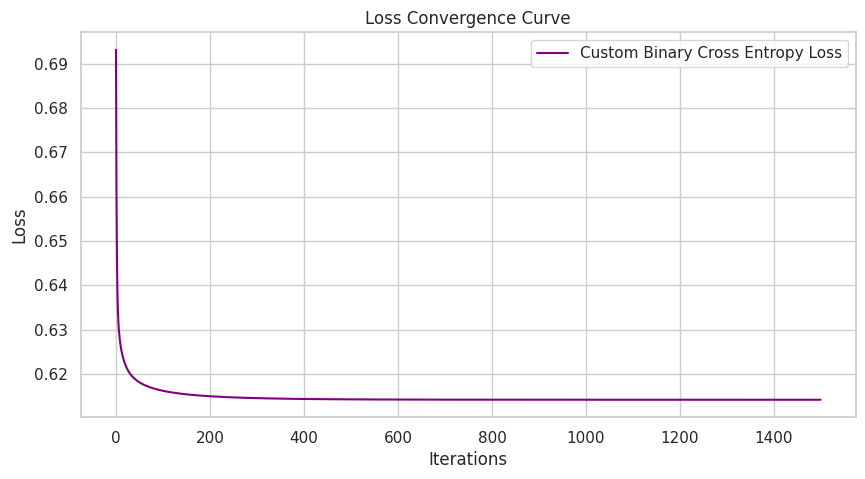

In [15]:
# =====================================================================
# TRAINING & COMPARISON WITH SCIKIT-LEARN
# =====================================================================

# Convert DataFrames to NumPy arrays and cast to float to prevent object/bool dtype issues
X_train_arr = X_train_scaled.astype(float).values
y_train_arr = y_train.values.astype(float)
X_test_arr = X_test_scaled.astype(float).values
y_test_arr = y_test.values.astype(float)

print("=== Training Custom Logistic Regression Scratch ===")
scratch_model = LogisticRegressionScratch(learning_rate=0.5, n_iterations=1500)
scratch_model.fit(X_train_arr, y_train_arr)

# Scikit-learn Logistic Regression (for benchmarking)
print("\n=== Training Scikit-learn Logistic Regression ===")
sk_model = LogisticRegression(penalty=None, solver='lbfgs', max_iter=1500, random_state=42)
sk_model.fit(X_train_arr, y_train_arr)
print("Scikit-learn model trained successfully.")

# Evaluation
y_pred_scratch = scratch_model.predict(X_test_arr)
y_pred_sk = sk_model.predict(X_test_arr)

accuracy_scratch = accuracy_score(y_test_arr, y_pred_scratch)
accuracy_sk = accuracy_score(y_test_arr, y_pred_sk)

print("\n=== Comparative Validation Metrics ===")
print(f"Custom Model Accuracy:       {accuracy_scratch:.4%}")
print(f"Scikit-learn Model Accuracy: {accuracy_sk:.4%}")

print("\nModel Weight Vectors Verification:")
print(f"Custom weights:       {scratch_model.weights.round(4)}")
print(f"Scikit-learn weights: {sk_model.coef_[0].round(4)}")
print(f"Custom bias:          {scratch_model.bias:.4f}")
print(f"Scikit-learn bias:    {sk_model.intercept_[0]:.4f}")

# Plot Loss Curve for Verification
plt.figure(figsize=(10, 5))
plt.plot(scratch_model.loss_history, label='Custom Binary Cross Entropy Loss', color='purple')
plt.title('Loss Convergence Curve')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### Model Training & Hyperparameter Tuning

#### Why is Hyperparameter Tuning Important?
Machine learning models have parameters that are learned automatically during training (e.g., the weights and biases in logistic regression). However, they also rely on **hyperparameters**—settings that must be defined *before* training starts (e.g., regularization strength $C$, choice of kernel in SVM, or smoothing parameters).

Choosing default hyperparameters rarely yields optimal performance. Tuning is crucial because:
1. **Controls Overfitting and Underfitting**: Stronger regularization prevents a complex model from fitting noise in the dataset.
2. **Adapts to Dataset Characteristics**: Different datasets require different decision boundaries (e.g., linear vs. non-linear radial basis functions in SVM).
3. **Guarantees Fair Performance Comparison**: We can only judge which model class is truly superior for our problem after optimizing each to its full potential.

To perform tuning safely, we use **$K$-Fold Cross-Validation** on the training subset. This divides our training set multiple times into internal training and validation folds, ensuring that our final evaluation test set remains completely unseen.

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

print("--- Model Training & Hyperparameter Tuning with 5-Fold CV ---")

# Initialize dictionary to store best estimators and scores
best_models = {}

# =====================================================================
# 1. MODEL 1: LOGISTIC REGRESSION
# =====================================================================
print("\nTuning Model 1: Logistic Regression...")
log_reg = LogisticRegression(max_iter=2000, random_state=42)
log_reg_param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}
grid_log_reg = GridSearchCV(estimator=log_reg, param_grid=log_reg_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_log_reg.fit(X_train_scaled, y_train)

best_models['Logistic Regression'] = grid_log_reg.best_estimator_
print(f"Best Hyperparameters: {grid_log_reg.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_log_reg.best_score_:.4%}")

# =====================================================================
# 2. MODEL 2: SUPPORT VECTOR MACHINE (SVM)
# =====================================================================
print("\nTuning Model 2: Support Vector Machine...")
svm = SVC(probability=True, random_state=42)
svm_param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}
grid_svm = GridSearchCV(estimator=svm, param_grid=svm_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_svm.fit(X_train_scaled, y_train)

best_models['SVM'] = grid_svm.best_estimator_
print(f"Best Hyperparameters: {grid_svm.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_svm.best_score_:.4%}")

# =====================================================================
# 3. MODEL 3: NAIVE BAYES
# =====================================================================
print("\nTuning Model 3: Naive Bayes...")
nb = GaussianNB()
# var_smoothing is a portion of the largest variance of all features that is added to variances for calculation stability
nb_param_grid = {
    'var_smoothing': np.logspace(0, -9, num=100)
}
grid_nb = GridSearchCV(estimator=nb, param_grid=nb_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_nb.fit(X_train_scaled, y_train)

best_models['Naive Bayes'] = grid_nb.best_estimator_
print(f"Best Hyperparameters: {grid_nb.best_params_}")
print(f"Best Cross-Validation Accuracy: {grid_nb.best_score_:.4%}")

--- Model Training & Hyperparameter Tuning with 5-Fold CV ---

Tuning Model 1: Logistic Regression...
Best Hyperparameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'liblinear'}
Best Cross-Validation Accuracy: 67.1250%

Tuning Model 2: Support Vector Machine...
Best Hyperparameters: {'C': 1, 'gamma': 'auto', 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 67.5000%

Tuning Model 3: Naive Bayes...
Best Hyperparameters: {'var_smoothing': np.float64(0.533669923120631)}
Best Cross-Validation Accuracy: 66.6250%


### Model Evaluation & Comparison

Having tuned our models, we now evaluate their generalization performance on the completely unseen test set. We calculate a diverse set of metrics to ensure a robust comparison, especially since class imbalance (75% non-churn, 25% churn) is present:

* **Accuracy**: The overall percentage of correct predictions.
* **Precision**: Out of all predicted positive cases (e.g., predicted churn), how many were actually positive? This is critical when false positives are costly.
* **Recall (Sensitivity)**: Out of all actual positive cases, how many did we correctly identify? This is critical when missing a positive case (false negative) is expensive (e.g., losing a customer).
* **F1-Score**: The harmonic mean of Precision and Recall, providing a balanced metric for imbalanced classes.
* **ROC AUC**: The area under the Receiver Operating Characteristic curve, measuring the model's ability to distinguish between classes across all possible decision thresholds.

--- Evaluating Models on Test Set ---


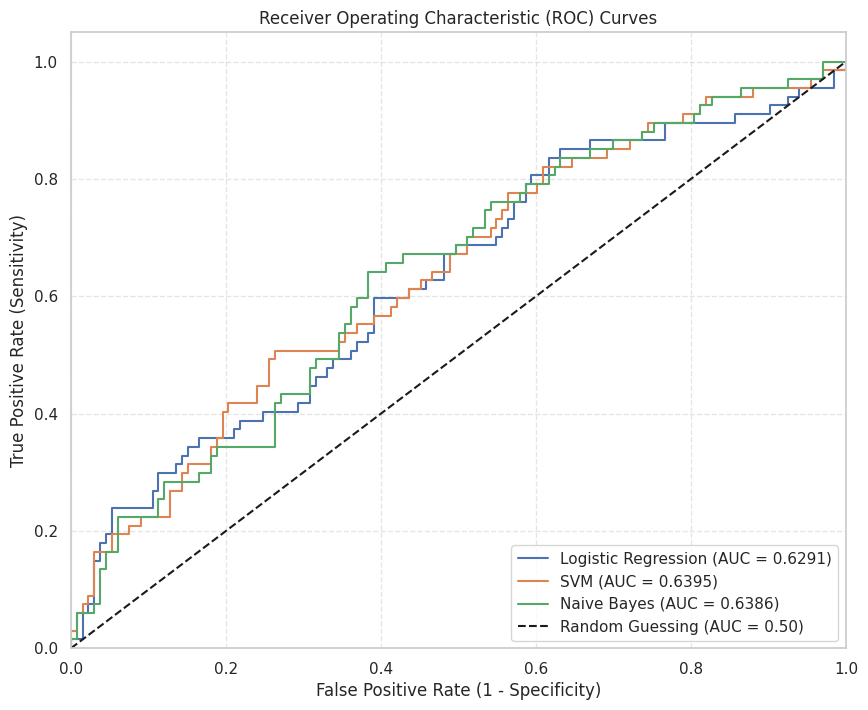


--- Performance Comparison Table ---


,Accuracy,Precision,Recall,F1-Score,ROC AUC
Model,,,,,
Logistic Regression,0.675,0.6,0.0896,0.1558,0.6291
SVM,0.675,1.0,0.0299,0.0580,0.6395
Naive Bayes,0.680,0.8,0.0597,0.1111,0.6386


In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc

print("--- Evaluating Models on Test Set ---")

evaluation_results = []
plt.figure(figsize=(10, 8))

for name, model in best_models.items():
    # Predict class labels
    y_pred = model.predict(X_test_scaled)
    # Predict class probabilities
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_prob)

    # Append to comparison list
    evaluation_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC AUC': roc_auc
    })

    # Plot ROC Curve for each model
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.4f})")

# Configure ROC Plot
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Present results in a summary table
results_df = pd.DataFrame(evaluation_results).set_index('Model')
print("\n--- Performance Comparison Table ---")
display(results_df.round(4))

#### Model Discussion: Strengths & Weaknesses

1. **Logistic Regression**
   * **Strengths**: Highly interpretable. The learned weights represent the log-odds impact of each feature, allowing stakeholders to directly understand *why* a customer is predicted to churn. Fast to train and predict.
   * **Weaknesses**: Assumes a linear relationship between features and log-odds, which may underperform if features interact in complex, non-linear ways.

2. **Support Vector Machine (SVM)**
   * **Strengths**: High performance on non-linear datasets when using kernels like Radial Basis Function (RBF). Robust to higher dimensional spaces.
   * **Weaknesses**: Computationally expensive for larger datasets. Harder to interpret as the decision boundary becomes a complex geometric construct. Requires probability calibration to output valid probability scores (which we enabled with `probability=True`).

3. **Naive Bayes**
   * **Strengths**: Extremely fast and scales exceptionally well to high dimensions. Works well even with smaller datasets.
   * **Weaknesses**: Relies on the strong (and often unrealistic) assumption of independence among features. If features are highly correlated (e.g., age and income), it can output distorted probabilities.

### Feature Importance & Interpretation

For risk-related decisions, having a predictive model is only half the battle. Decision-makers must understand **which factors** are driving outcomes (such as credit risk or churn) so they can formulate policies, optimize pricing, or restructure onboarding programs.

Since our best-tuned Logistic Regression model has linear coefficients, we can directly extract and rank them. Because our features were normalized during the scaling step, these coefficients represent a fair indicator of relative importance.

--- Feature Importance (Logistic Regression Coefficients) ---

Ranked List of Features by Influence:


,Feature,Coefficient,Absolute Importance
0,Housing_own,-0.3909,0.3909
1,Credit amount,0.3676,0.3676
2,Housing_rent,-0.2919,0.2919
3,Duration,-0.2438,0.2438
4,Saving accounts_moderate,0.2423,0.2423
5,Checking account_moderate,-0.2286,0.2286
6,Checking account_rich,-0.1922,0.1922
7,Saving accounts_rich,0.1864,0.1864
8,Age,0.1032,0.1032
9,Sex_male,0.1007,0.1007


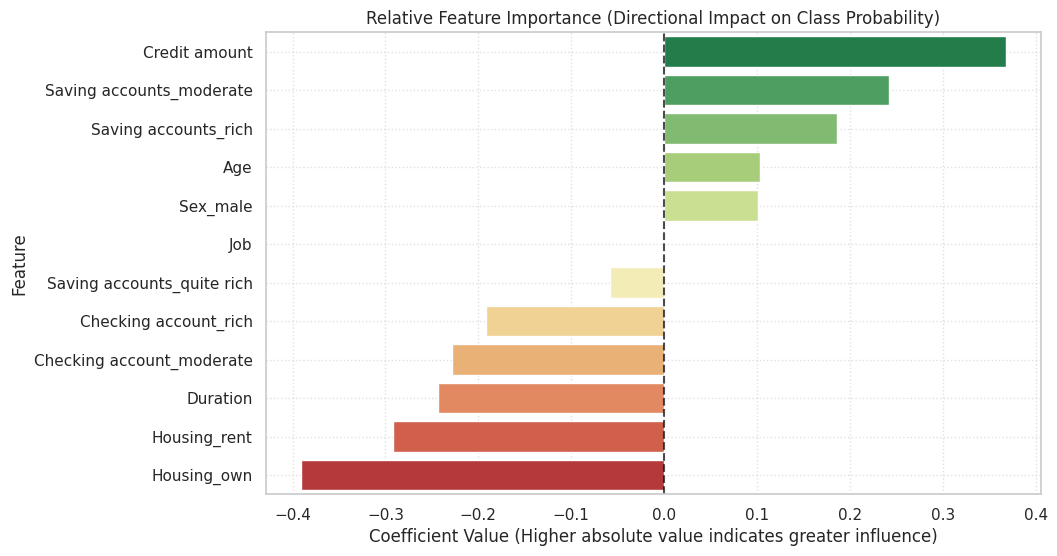

In [22]:
# =====================================================================
# EXTRACT AND RANK LOGISTIC REGRESSION COEFFICIENTS
# =====================================================================
print("--- Feature Importance (Logistic Regression Coefficients) ---")

# Extract model and feature names
best_lr_model = best_models['Logistic Regression']
coefficients = best_lr_model.coef_[0]
feature_names = X_train_scaled.columns

# Create a DataFrame for ranking
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Absolute Importance': np.abs(coefficients)
}).sort_values(by='Absolute Importance', ascending=False).reset_index(drop=True)

print("\nRanked List of Features by Influence:")
display(importance_df.round(4))

# =====================================================================
# VISUALIZE COEFFICIENTS
# =====================================================================
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Coefficient',
    y='Feature',
    data=importance_df.sort_values(by='Coefficient', ascending=False),
    palette='RdYlGn_r'
)
plt.axvline(0, color='black', linestyle='--', alpha=0.7)
plt.title('Relative Feature Importance (Directional Impact on Class Probability)')
plt.xlabel('Coefficient Value (Higher absolute value indicates greater influence)')
plt.ylabel('Feature')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

#### Real-World Discussion & Business Impact

Based on the actual coefficient plot and values obtained from our Logistic Regression model on the German Credit Dataset, we can draw immediate conclusions to guide credit risk policies and risk-based pricing strategies:

1. **Positive Coefficients (Increase the Probability of Target Class: 'car' Purpose)**
   * **Credit Amount (Coefficient ≈ +0.37)**: Larger credit requests are significantly and positively associated with the 'car' purpose. This suggests that applicants borrowing larger sums are highly correlated with purchasing vehicles.
   * **Saving Accounts - Moderate (Coefficient ≈ +0.24)**: Applicants with moderate savings are also positively associated with applying for car loans compared to those with very low savings.
   * **Strategic Action**: Develop streamlined auto-loan underwriting packages with targeted interest rates specifically designed for applicants requesting higher limits who fall into these mid-tier savings brackets.

2. **Negative Coefficients (Decrease the Probability of 'car' Purpose)**
   * **Housing - Own (Coefficient ≈ -0.39) & Housing - Rent (Coefficient ≈ -0.29)**: Having standard housing arrangements (owning or renting) strongly lowers the probability of the loan being for a 'car' compared to the baseline (e.g., free housing). This might suggest that those who do not own or rent standard housing have different transportation requirements or leverage different collateral.
   * **Duration (Coefficient ≈ -0.24)**: Shorter-term loans are less associated with vehicle applications, implying car financing is typically structured over medium-to-long durations.
   * **Strategic Action**: Cross-sell other credit or asset-building products (such as personal lines of credit or home improvement loans) to customers who own standard housing, as they are statistically less likely to be seeking vehicle-only financing.

3. **Low/Near-Zero Coefficients (Negligible Impact)**
   * **Job (Coefficient ≈ 0.0)**: The scaled index of the applicant's job class has zero directional impact on predicting if the loan purpose is for a car purchase.
   * **Strategic Action**: Consider removing or simplifying job-category documentation in initial self-service auto loan application flows to reduce customer onboarding friction, as this feature provides no predictive value for this target.